# Intelligent Firewall Traffic Analyzer
## Notebook 01 — Exploratory Data Analysis and Cleaning

### Research Objective

Explore the Internet Firewall Data dataset to understand
traffic characteristics and their relationships with
firewall actions.

### Dataset
- Source: UCI Machine Learning Repository
- Observations: 65,532
- Columns: 12
- Target: Action (allow, deny, drop, reset-both)

### Methodology
1. Data quality assessment
2. Univariate and bivariate analysis
3. Correlation analysis
4. Statistical hypothesis testing
5. Destination port analysis
6. Outlier investigation
7. Duplicate and label-conflict analysis
8. Preprocessing recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/log2.csv")

df.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


In [3]:
print("Shape :", df.shape)
print("\nColumns :")
print(df.columns.tolist())

print("\nData types :")
print(df.dtypes)
df.info()
df.describe()

Shape : (65532, 12)

Columns :
['Source Port', 'Destination Port', 'NAT Source Port', 'NAT Destination Port', 'Action', 'Bytes', 'Bytes Sent', 'Bytes Received', 'Packets', 'Elapsed Time (sec)', 'pkts_sent', 'pkts_received']

Data types :
Source Port             int64
Destination Port        int64
NAT Source Port         int64
NAT Destination Port    int64
Action                    str
Bytes                   int64
Bytes Sent              int64
Bytes Received          int64
Packets                 int64
Elapsed Time (sec)      int64
pkts_sent               int64
pkts_received           int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 65532 entries, 0 to 65531
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Source Port           65532 non-null  int64
 1   Destination Port      65532 non-null  int64
 2   NAT Source Port       65532 non-null  int64
 3   NAT Destination Port  65532 non-null  in

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
count,65532.000000,65532.000000,65532.000000,65532.000000,6.553200e+04,6.553200e+04,6.553200e+04,6.553200e+04,65532.000000,65532.000000,65532.000000
mean,49391.969343,10577.385812,19282.972761,2671.049930,9.712395e+04,2.238580e+04,7.473815e+04,1.028660e+02,65.833577,41.399530,61.466505
std,15255.712537,18466.027039,21970.689669,9739.162278,5.618439e+06,3.828139e+06,2.463208e+06,5.133002e+03,302.461762,3218.871288,2223.332271
min,0.000000,0.000000,0.000000,0.000000,6.000000e+01,6.000000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
25%,49183.000000,80.000000,0.000000,0.000000,6.600000e+01,6.600000e+01,0.000000e+00,1.000000e+00,0.000000,1.000000,0.000000
50%,53776.500000,445.000000,8820.500000,53.000000,1.680000e+02,9.000000e+01,7.900000e+01,2.000000e+00,15.000000,1.000000,1.000000
75%,58638.000000,15000.000000,38366.250000,443.000000,7.522500e+02,2.100000e+02,4.490000e+02,6.000000e+00,30.000000,3.000000,2.000000
max,65534.000000,65535.000000,65535.000000,65535.000000,1.269359e+09,9.484772e+08,3.208818e+08,1.036116e+06,10824.000000,747520.000000,327208.000000


In [4]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Count"))

# Duplicates
duplicates = df.duplicated().sum()
percentage = duplicates / len(df) * 100

print(f"\nDuplicate rows: {duplicates}")
print(f"Duplicate percentage: {percentage:.2f}%")

# Target class distribution
print("\nFirewall Action Distribution:")

class_distribution = pd.DataFrame({
    "Count": df["Action"].value_counts(),
    "Percentage": df["Action"].value_counts(normalize=True) * 100
})

display(class_distribution)

Missing values per column:


,Missing Count
Source Port,0
Destination Port,0
NAT Source Port,0
NAT Destination Port,0
Action,0
Bytes,0
Bytes Sent,0
Bytes Received,0
Packets,0
Elapsed Time (sec),0



Duplicate rows: 8362
Duplicate percentage: 12.76%

Firewall Action Distribution:


,Count,Percentage
Action,,
allow,37640,57.437588
deny,14987,22.869743
drop,12851,19.610267
reset-both,54,0.082402


### Initial Data Quality Findings

The Internet Firewall Data dataset contains 65,532 network traffic observations and 12 columns, including the target variable `Action`.

The initial inspection reveals no missing values. However, 8,362 rows are exact duplicates, representing approximately 12.76% of the dataset.

The target variable is highly imbalanced. The majority class is `allow` (57.44%), whereas `reset-both` accounts for only 0.0824% of the observations.

These findings require further investigation before preprocessing. In particular, duplicated records should not be removed without evaluating their meaning and potential influence on model performance.

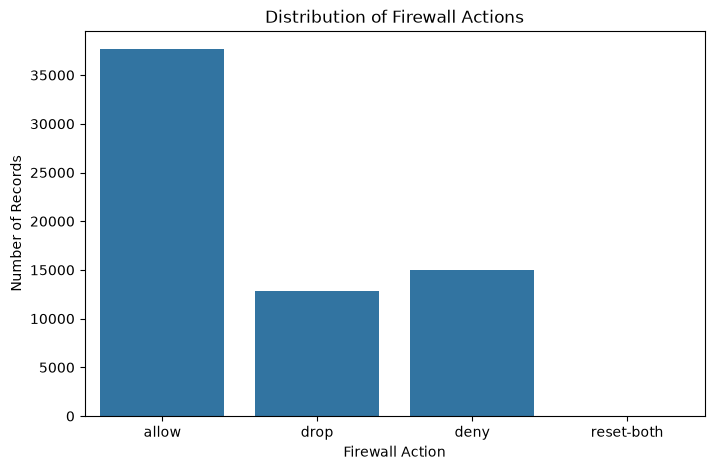

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Action"
)

plt.title("Distribution of Firewall Actions")
plt.xlabel("Firewall Action")
plt.ylabel("Number of Records")

plt.show()

## 2. Duplicate Records Analysis

In [6]:
# Rows belonging to a repeated group
duplicate_mask = df.duplicated(keep=False)

print("Total rows belonging to duplicate groups:")
print(duplicate_mask.sum())

print("\nDuplicate-group distribution by firewall action:")
display(df.loc[duplicate_mask, "Action"].value_counts())

print("\nSample repeated records:")
display(df.loc[duplicate_mask].head(10))

Total rows belonging to duplicate groups:
13281

Duplicate-group distribution by firewall action:


Action
deny     10632
drop      2403
allow      246
Name: count, dtype: int64


Sample repeated records:


,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
141,51048,445,0,0,drop,70,70,0,1,0,1,0
147,55724,445,0,0,drop,70,70,0,1,0,1,0
148,51125,445,0,0,drop,66,66,0,1,0,1,0
151,51121,445,0,0,drop,66,66,0,1,0,1,0
154,51120,445,0,0,drop,66,66,0,1,0,1,0
157,51041,445,0,0,drop,70,70,0,1,0,1,0
162,51039,445,0,0,drop,70,70,0,1,0,1,0
164,57015,42707,0,0,deny,62,62,0,1,0,1,0
165,41213,25174,0,0,deny,62,62,0,1,0,1,0
166,57131,8055,0,0,deny,145,145,0,1,0,1,0


## 3. Univariate Analysis

### 3.1 Distribution of Numerical Features

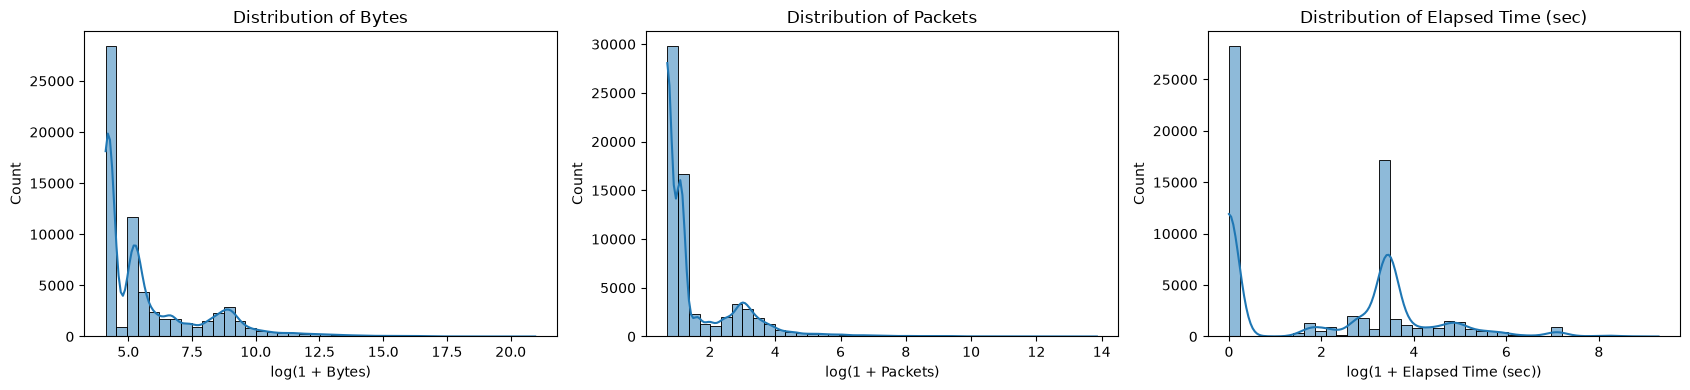

In [7]:
traffic_features = [
    "Bytes",
    "Packets",
    "Elapsed Time (sec)"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, feature in zip(axes, traffic_features):
    sns.histplot(
        np.log1p(df[feature]),
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(f"log(1 + {feature})")

plt.tight_layout()
plt.show()

## 4. Bivariate Analysis

### 4.1 Traffic Volume by Firewall Action

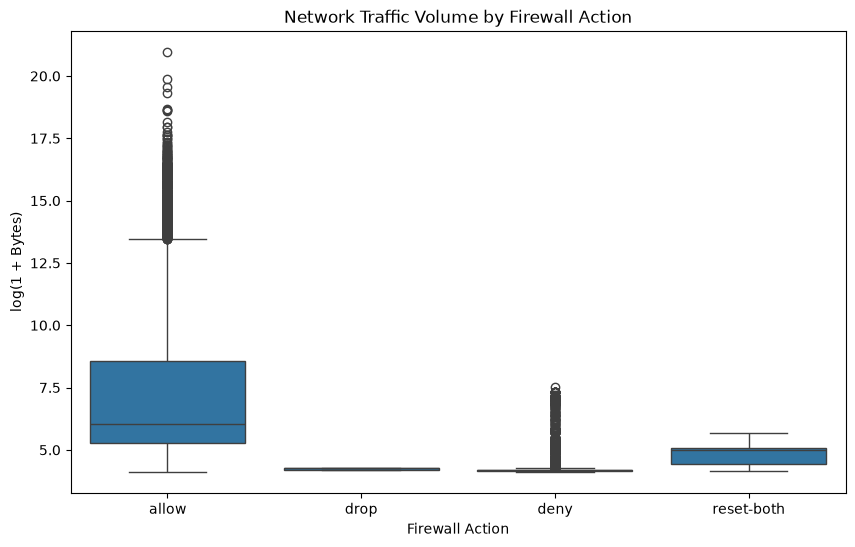

In [8]:
df_plot = df.copy()

df_plot["Log Bytes"] = np.log1p(df_plot["Bytes"])

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_plot,
    x="Action",
    y="Log Bytes",
    showfliers=True
)

plt.title("Network Traffic Volume by Firewall Action")
plt.xlabel("Firewall Action")
plt.ylabel("log(1 + Bytes)")

plt.show()

## 5. Correlation Analysis

### 5.1 Spearman Correlation Matrix

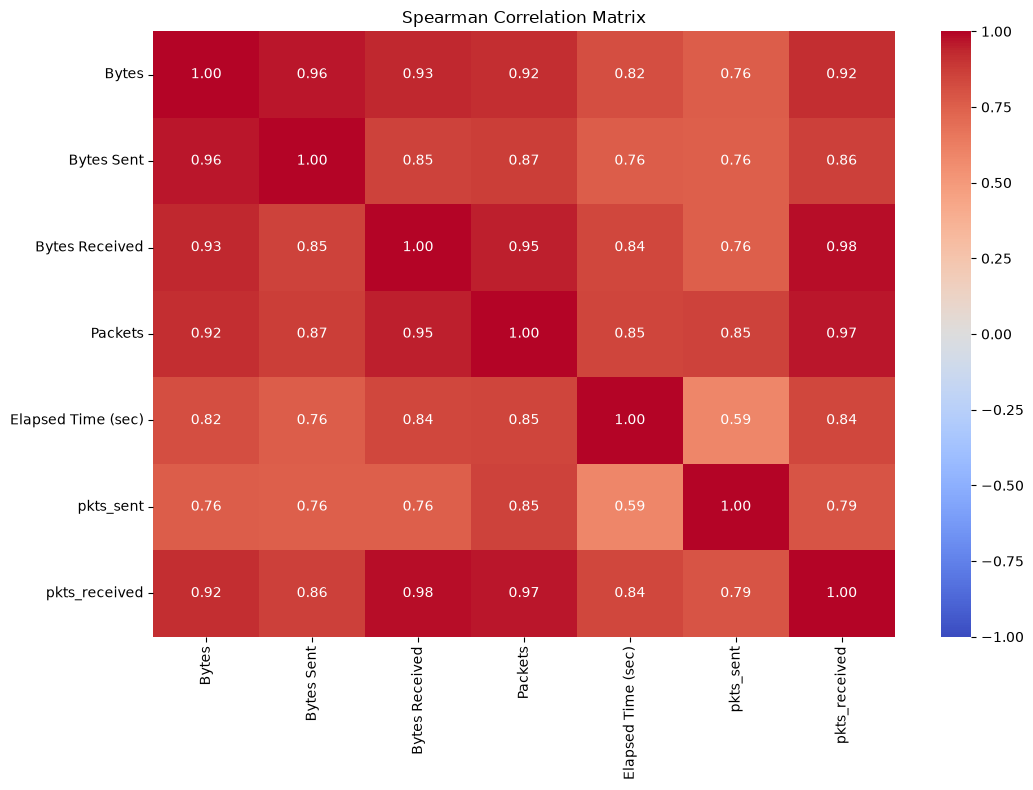

In [9]:
traffic_columns = [
    "Bytes",
    "Bytes Sent",
    "Bytes Received",
    "Packets",
    "Elapsed Time (sec)",
    "pkts_sent",
    "pkts_received"
]

corr = df[traffic_columns].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [10]:
print(
    "Bytes consistency:",
    (df["Bytes"] == df["Bytes Sent"] + df["Bytes Received"]).mean()
)

print(
    "Packets consistency:",
    (df["Packets"] == df["pkts_sent"] + df["pkts_received"]).mean()
)

Bytes consistency: 1.0
Packets consistency: 1.0


## 6. Statistical Hypothesis Testing

### 6.1 Kruskal–Wallis Test: Traffic Volume by Firewall Action

Objective: Determine whether the distribution of transferred bytes
differs significantly among the four firewall actions.

H0: The four action groups have identical byte-volume distributions.

H1: At least one action group has a different distribution.

Significance level: alpha = 0.05.

In [11]:
from scipy.stats import kruskal

groups = [
    df.loc[df["Action"] == action, "Bytes"]
    for action in sorted(df["Action"].unique())
]

H, p_value = kruskal(*groups)

n = len(df)
k = len(groups)

epsilon_squared = max(0, (H - k + 1) / (n - k))

print(f"Kruskal-Wallis H statistic: {H:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Epsilon-squared: {epsilon_squared:.4f}")

if p_value < 0.05:
    print("Reject H0: a statistically significant difference exists.")
else:
    print("Fail to reject H0.")

Kruskal-Wallis H statistic: 44287.9946
P-value: 0
Epsilon-squared: 0.6758
Reject H0: a statistically significant difference exists.


### 6.2 Chi-Square Independence Test

Objective: Investigate whether the presence or absence of a
recorded NAT source port is associated with firewall action.

H0: NAT source port status and firewall action are independent.

H1: NAT source port status and firewall action are associated.

Significance level: alpha = 0.05.

In [12]:
from scipy.stats import chi2_contingency

nat_status = np.where(
    df["NAT Source Port"] == 0,
    "Zero",
    "Non-zero"
)

contingency_table = pd.crosstab(
    nat_status,
    df["Action"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

n = contingency_table.to_numpy().sum()
r, c = contingency_table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")
print(f"Cramer's V: {cramers_v:.4f}")
print(f"Minimum expected frequency: {expected.min():.2f}")

if expected.min() < 5:
    print("Warning: inspect expected frequencies before interpreting the test.")
elif p_value < 0.05:
    print("Reject H0: significant association exists.")
else:
    print("Fail to reject H0.")

Action,allow,deny,drop,reset-both
row_0,,,,
Non-zero,37076,12,0,12
Zero,564,14975,12851,42


Chi-square statistic: 63183.4191
P-value: 0
Degrees of freedom: 3
Cramer's V: 0.9819
Minimum expected frequency: 23.43
Reject H0: significant association exists.


### Interpretation of the Kruskal–Wallis Test

The Kruskal–Wallis test produced H = 44287.9946,
with an extremely small p-value.

Since p < 0.05, we reject the null hypothesis.

This indicates statistically significant differences
in traffic-volume distributions among firewall actions.

The estimated epsilon-squared effect size (0.6758)
suggests a substantial association between firewall
action groups and transferred bytes.

However, the test does not identify which pairs of
firewall actions differ. Post-hoc comparisons are
necessary for that purpose.

### Interpretation of the Chi-Square Test

The chi-square independence test produced:

- Chi-square statistic: 63183.4191
- Degrees of freedom: 3
- Extremely small p-value
- Cramer's V: 0.9819

We reject the null hypothesis of independence.

There is an exceptionally strong association between
NAT source-port status and firewall action.

However, this association is not evidence of causation.

The NAT source-port attribute may encode information
related to firewall processing decisions.

This potential information leakage will be investigated
during the preprocessing and modeling phases.

## 7. Destination Port Analysis

### 7.1 Most Frequent Destination Ports

Objective: Identify the most frequently used destination
ports and investigate their relationship with firewall actions.

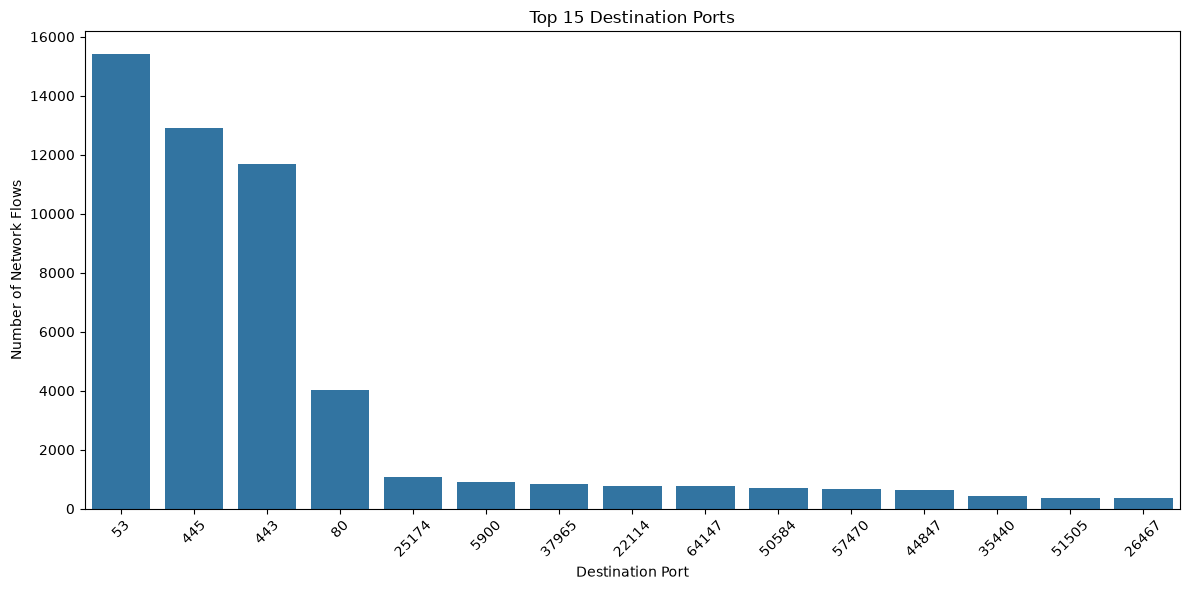

In [13]:
# Most frequent destination ports
top_ports = df["Destination Port"].value_counts().head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_ports.index.astype(str),
    y=top_ports.values
)

plt.title("Top 15 Destination Ports")
plt.xlabel("Destination Port")
plt.ylabel("Number of Network Flows")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 7.2 Firewall Action Distribution by Destination Port

Objective: Investigate how the distribution of firewall actions
varies among the most frequently observed destination ports.

Action,allow,deny,drop
Destination Port,,,
53,15385,29,0
80,4028,7,0
443,11677,7,0
445,0,40,12851
5900,55,854,0
22114,0,767,0
25174,0,1087,0
37965,0,826,0
50584,0,717,0


Action,allow,deny,drop
Destination Port,,,
53,99.81,0.19,0.00
80,99.83,0.17,0.00
443,99.94,0.06,0.00
445,0.00,0.31,99.69
5900,6.05,93.95,0.00
22114,0.00,100.00,0.00
25174,0.00,100.00,0.00
37965,0.00,100.00,0.00
50584,0.00,100.00,0.00


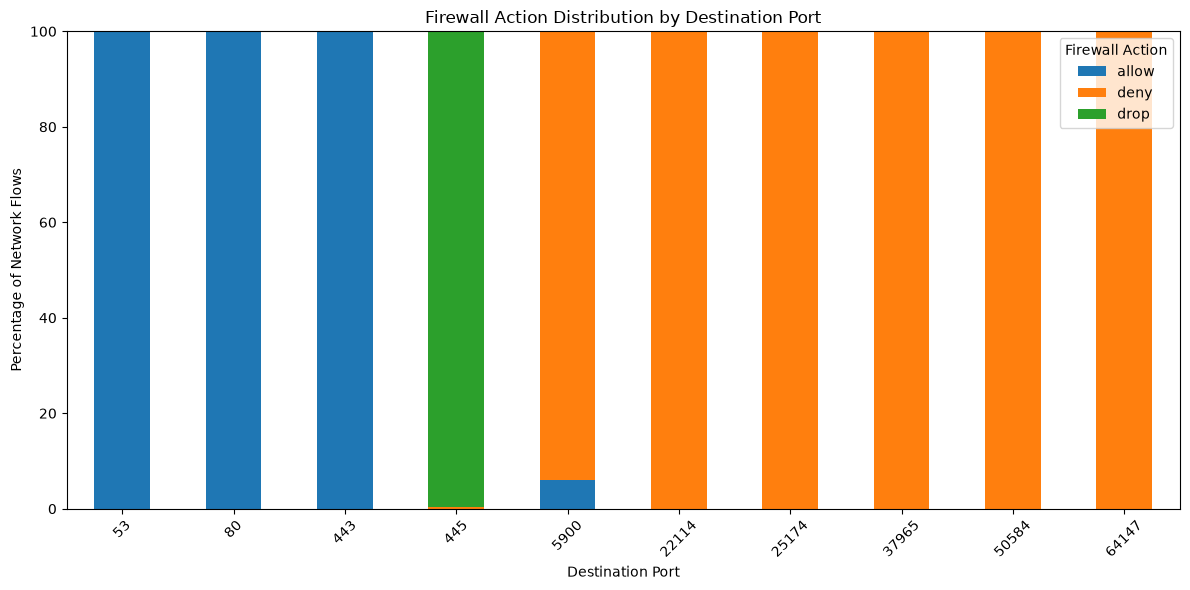

In [14]:
# Select the 10 most frequent destination ports
top_10_ports = df["Destination Port"].value_counts().head(10).index

# Keep only records using those ports
df_ports = df[df["Destination Port"].isin(top_10_ports)]

# Count firewall actions per destination port
port_action = pd.crosstab(
    df_ports["Destination Port"],
    df_ports["Action"]
)

display(port_action)

# Convert counts to percentages within each port
port_action_percent = (
    port_action.div(port_action.sum(axis=1), axis=0) * 100
)

display(port_action_percent.round(2))

# Visualize
port_action_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Firewall Action Distribution by Destination Port")
plt.xlabel("Destination Port")
plt.ylabel("Percentage of Network Flows")
plt.legend(title="Firewall Action")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Outlier Analysis

Objective: Investigate extreme values in network traffic
volume, packet counts and connection duration before
making any cleaning decisions.

In [15]:
features = [
    "Bytes",
    "Packets",
    "Elapsed Time (sec)"
]

for feature in features:
    print(f"\n===== {feature} =====")

    print(df[feature].describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    ))

    q99 = df[feature].quantile(0.99)

    print("Observations above 99th percentile:",
          (df[feature] > q99).sum())


===== Bytes =====
count    6.553200e+04
mean     9.712395e+04
std      5.618439e+06
min      6.000000e+01
25%      6.600000e+01
50%      1.680000e+02
75%      7.522500e+02
95%      2.041145e+04
99%      5.200019e+05
max      1.269359e+09
Name: Bytes, dtype: float64
Observations above 99th percentile: 656

===== Packets =====
count    6.553200e+04
mean     1.028660e+02
std      5.133002e+03
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      6.000000e+00
95%      5.000000e+01
99%      6.270000e+02
max      1.036116e+06
Name: Packets, dtype: float64
Observations above 99th percentile: 655

===== Elapsed Time (sec) =====
count    65532.000000
mean        65.833577
std        302.461762
min          0.000000
25%          0.000000
50%         15.000000
75%         30.000000
95%        194.000000
99%       1200.000000
max      10824.000000
Name: Elapsed Time (sec), dtype: float64
Observations above 99th percentile: 407


## 9. Cleaning Strategy Investigation

### 9.1 Impact of Duplicate Removal

Before deciding whether to remove exact duplicates,
we compare the original class distribution with
the distribution obtained after duplicate removal.

The raw dataset remains unchanged.

In [16]:
df_unique = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Unique rows:", len(df_unique))
print("Removed duplicates:", len(df) - len(df_unique))

comparison = pd.DataFrame({
    "Original (%)":
        df["Action"].value_counts(normalize=True) * 100,
    "Without Duplicates (%)":
        df_unique["Action"].value_counts(normalize=True) * 100
})

display(comparison.round(3))

Original rows: 65532
Unique rows: 57170
Removed duplicates: 8362


,Original (%),Without Duplicates (%)
Action,,
allow,57.438,65.487
deny,22.870,14.067
drop,19.610,20.352
reset-both,0.082,0.094


In [17]:
feature_columns = df.columns.drop("Action").tolist()

label_counts = (
    df.groupby(feature_columns, dropna=False)["Action"]
    .nunique()
)

conflicting_groups = (label_counts > 1).sum()

print(
    "Feature combinations associated with multiple actions:",
    conflicting_groups
)

Feature combinations associated with multiple actions: 9


### 9.2 Conflicting Target Labels

We investigate whether identical network traffic
features can correspond to different firewall actions.

Such conflicts may indicate missing contextual
information or ambiguity in the recorded data.

In [18]:
feature_columns = df.columns.drop("Action").tolist()

# Find feature combinations having multiple labels
group_summary = (
    df.groupby(feature_columns, dropna=False)["Action"]
    .agg(n_actions="nunique", n_records="size")
    .reset_index()
)

conflicts = group_summary[
    group_summary["n_actions"] > 1
]

print("Conflicting feature combinations:", len(conflicts))

# Retrieve all observations involved
conflict_rows = df.merge(
    conflicts[feature_columns],
    on=feature_columns,
    how="inner"
)

print("Total observations involved:", len(conflict_rows))

print("\nActions among conflicting observations:")
display(conflict_rows["Action"].value_counts())

display(conflict_rows.head(15))

Conflicting feature combinations: 9
Total observations involved: 46

Actions among conflicting observations:


Action
deny     28
allow    10
drop      8
Name: count, dtype: int64

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,50995,445,0,0,drop,66,66,0,1,0,1,0
1,50672,445,0,0,drop,70,70,0,1,0,1,0
2,55308,445,0,0,drop,70,70,0,1,0,1,0
3,54216,445,0,0,drop,70,70,0,1,0,1,0
4,53543,445,0,0,drop,70,70,0,1,0,1,0
5,65125,445,0,0,deny,70,70,0,1,0,1,0
6,0,0,0,0,deny,156,156,0,2,0,2,0
7,0,0,0,0,deny,156,156,0,2,0,2,0
8,0,0,0,0,deny,156,156,0,2,0,2,0
9,0,0,0,0,deny,156,156,0,2,0,2,0


In [19]:
from scipy.stats import kruskal, chi2_contingency

df_sensitivity = df.drop_duplicates().copy()

# Kruskal-Wallis
groups_unique = [
    df_sensitivity.loc[
        df_sensitivity["Action"] == action, "Bytes"
    ]
    for action in sorted(df_sensitivity["Action"].unique())
]

H_unique, p_unique = kruskal(*groups_unique)

print("Kruskal-Wallis on unique rows:")
print("H =", H_unique)
print("p-value =", p_unique)

# Chi-square
nat_status_unique = np.where(
    df_sensitivity["NAT Source Port"] == 0,
    "Zero",
    "Non-zero"
)

table_unique = pd.crosstab(
    nat_status_unique,
    df_sensitivity["Action"]
)

chi2_unique, p_chi_unique, dof, expected = chi2_contingency(
    table_unique
)

print("\nChi-square on unique rows:")
print("Chi-square =", chi2_unique)
print("p-value =", p_chi_unique)
print("Minimum expected count =", expected.min())

Kruskal-Wallis on unique rows:
H = 34770.939451743136
p-value = 0.0

Chi-square on unique rows:
Chi-square = 55264.49930891613
p-value = 0.0
Minimum expected count = 19.009095679552214


## 10. EDA Summary and Preprocessing Recommendations

### Main Findings

1. The dataset contains 65,532 observations and 12 columns.
2. No missing values were detected.
3. Exact duplicated observations were identified and analyzed.
4. The target variable is highly imbalanced, especially for reset-both.
5. Traffic-volume and packet-count variables are strongly right-skewed.
6. Some numerical features are mathematically redundant.
7. Firewall actions are strongly associated with destination ports and NAT source-port status.
8. Two statistical hypothesis tests detected significant associations.
### Duplicate and Label-Conflict Sensitivity Analysis

After exact duplicate removal, the dataset contains
57,170 observations instead of 65,532.

Nine distinct feature combinations are associated
with multiple firewall actions, involving 46 records.

The Kruskal-Wallis and Chi-square tests remain
statistically significant after deduplication,
indicating that the observed associations are
not solely driven by exact duplicate records.

However, the independence of observations cannot
be established from the available dataset.

The modeling phase will compare appropriate
duplicate-handling strategies and investigate
possible information leakage from NAT attributes
and post-connection traffic statistics.

### Proposed Preprocessing Strategy

- Preserve the original raw dataset.
- Evaluate duplicate removal using its effect on class distributions and model validation.
- Avoid automatic deletion of extreme traffic values.
- Apply appropriate transformations and scaling within the training pipeline.
- Preserve all four target classes.
- Use stratified splitting and cross-validation where appropriate.
- Compare models with and without features that may leak firewall decision outcomes.

The final preprocessing choices will be validated experimentally in Notebook 02 and Notebook 03.